# SnapWave vs SWAN: metamodel cases

The same training cases (same LHS, boundary forcing and water level) in both
models, **without wind**, to help select a model for the Netherlands. Run it
any time: SWAN cases are read from their folders, so it uses the cases finished
so far (notebook 05, with `simulations.model` set to each model).

In the metrics SnapWave is the reference (bias = SWAN − SnapWave), by convention
only: these cases have no observations, so this shows how the models differ, not
which is right. That is notebook `08c_Compare_Models_Dynamic`.

**Hs ratio**: `sqrt(sum SWAN² / sum SnapWave²)`, so it weighs energy. Sites with
less than 10 % of the offshore Hs are left out where noted: in a case that forces
one goal most sites get almost nothing, and pointwise ratios there are noise.

In [ ]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

import numpy as np
from utils import model_comparison as mc
from utils import validation as val
from utils.config import load_goals

## 1 · Load the cases

In [2]:
goals = load_goals()
snapwave = mc.load_snapwave_metamodel(goals)
swan = mc.load_swan(snapwave)
snapwave = snapwave.sel(case_num=swan.case_num)
print(f"{swan.sizes['case_num']} SWAN cases finished")
swan["goal"].to_series().value_counts().sort_index().rename("cases")

4426 SWAN cases finished


goal
1    629
2    629
3    629
4    629
5    629
6    629
7    608
8     44
Name: cases, dtype: int64

## 2 · Metrics per site group

On the sites that get energy: direction and spreading mean nothing elsewhere. The
first cases to finish are the fast ones and the goals run in order: while the
SWAN array is running, this sample is not representative.

In [ ]:
comparison = val.compare(
    mc.energetic(snapwave, snapwave),
    mc.energetic(swan, snapwave),
    variables=mc.VARIABLES,
    reference_label="SnapWave",
    estimate_label="SWAN",
)
columns = ["n", "bias", "rmse", "r2"]
comparison.metrics.query("site_source != 'buoy'").set_index(["group", "variable"])[
    columns
].round(3)

n   bias    rmse     r2
group    variable                               
5m       hs        2153000 -0.292   0.485  0.546
         tp        2152384 -0.035   0.404  0.982
         dir       2152944  1.914  35.646  0.506
         spr       2152944 -2.170  10.231  0.019
10m      hs        3403457 -0.330   0.542  0.623
         tp        3403047 -0.090   0.521  0.970
         dir       3403432  2.633  39.817  0.512
         spr       3403432 -1.949   9.749  0.095
20m      hs        3673936 -0.256   0.420  0.835
         tp        3673700 -0.140   0.522  0.970
         dir       3673841  2.055  27.463  0.777
         spr       3673841 -1.906   8.281  0.043
DeenHaag hs         305668 -0.259   0.371  0.845
         tp         305641 -0.092   0.321  0.988
         dir        305663  3.748  27.847  0.736
         spr        305663 -2.358   8.988 -0.203

In [ ]:
# Median over the buoy sites
comparison.metrics.query("site_source == 'buoy'").groupby("variable")[
    columns
].median().round(3)

,n,bias,rmse,r2
variable,,,,
dir,2023.0,2.600,29.820,0.623
hs,2023.0,-0.264,0.380,0.821
spr,2023.0,-2.314,9.072,-0.125
tp,2022.5,-0.130,0.574,0.963


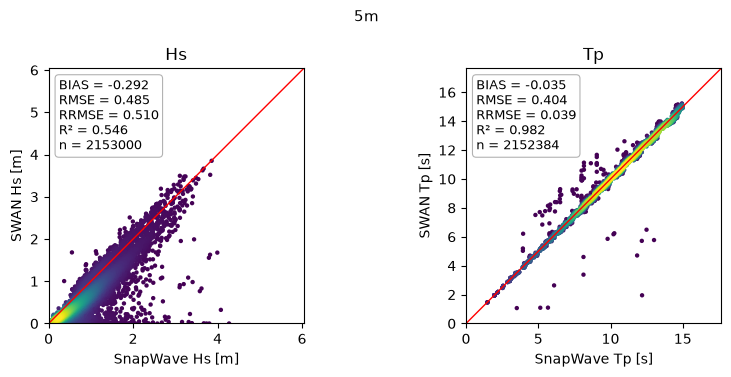

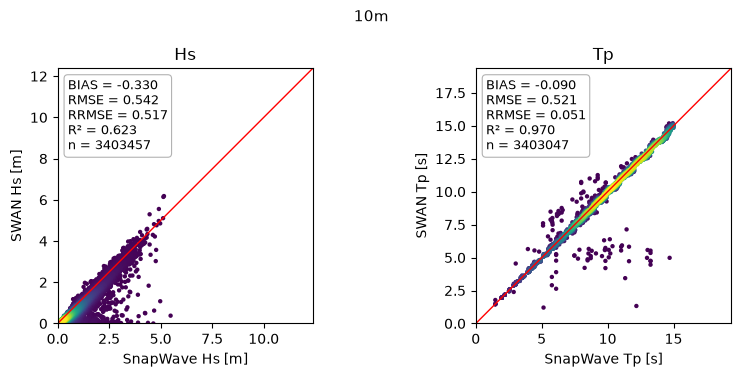

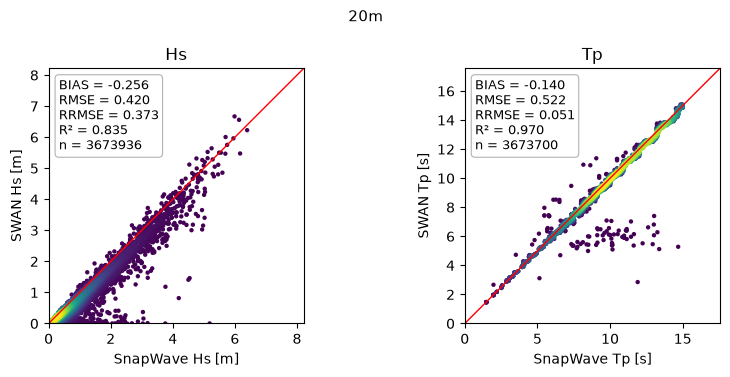

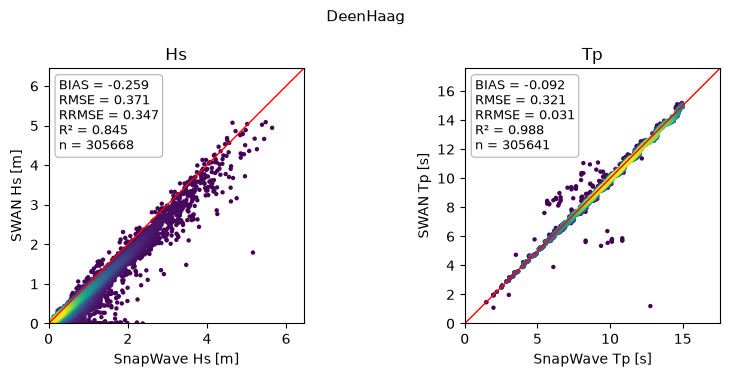

In [5]:
for group in ["5m", "10m", "20m", "DeenHaag"]:
    comparison.plot_scatter(group, variables=["hs", "tp"])

## 3 · Hs ratio per goal and offshore direction

Median over the cases of each cell, on the sites that get energy. Low values at
the directions pointing out of the domain mean SWAN lets that energy leave, which
matters only if the hindcast has energy there.

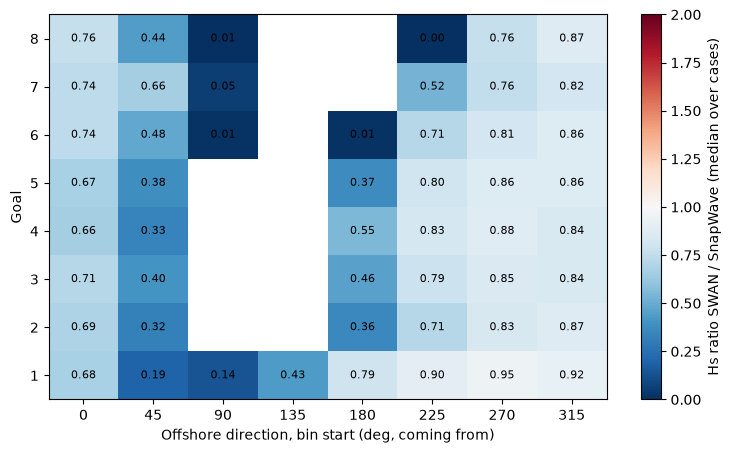

In [6]:
table = mc.goal_direction_ratio(snapwave, swan)
mc.plot_goal_direction(table);

## 4 · Hs ratio per site

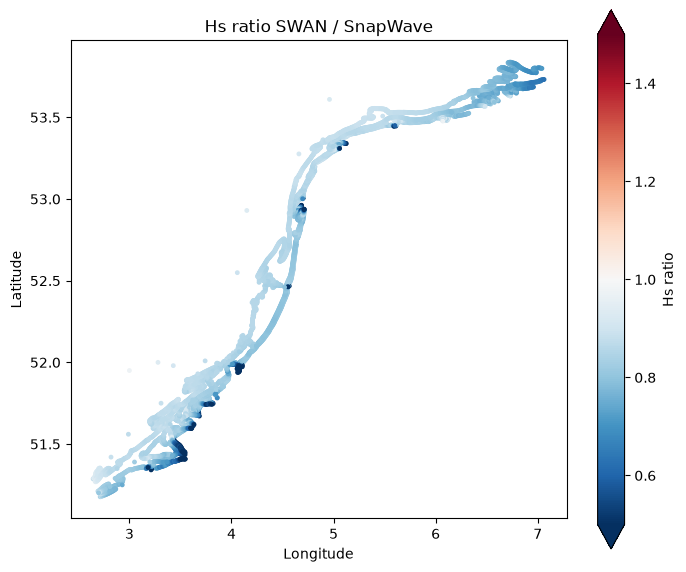

In [7]:
energetic_hs = mc.energetic(snapwave, snapwave)["hs"]
mc.plot_site_ratio(mc.hs_ratio(energetic_hs, swan["hs"], "case_num"));

## 5 · Grid maps

The cases with a map in both models: the strongest offshore Hs, and the largest
disagreement in energy.

453 cases with a map in both models


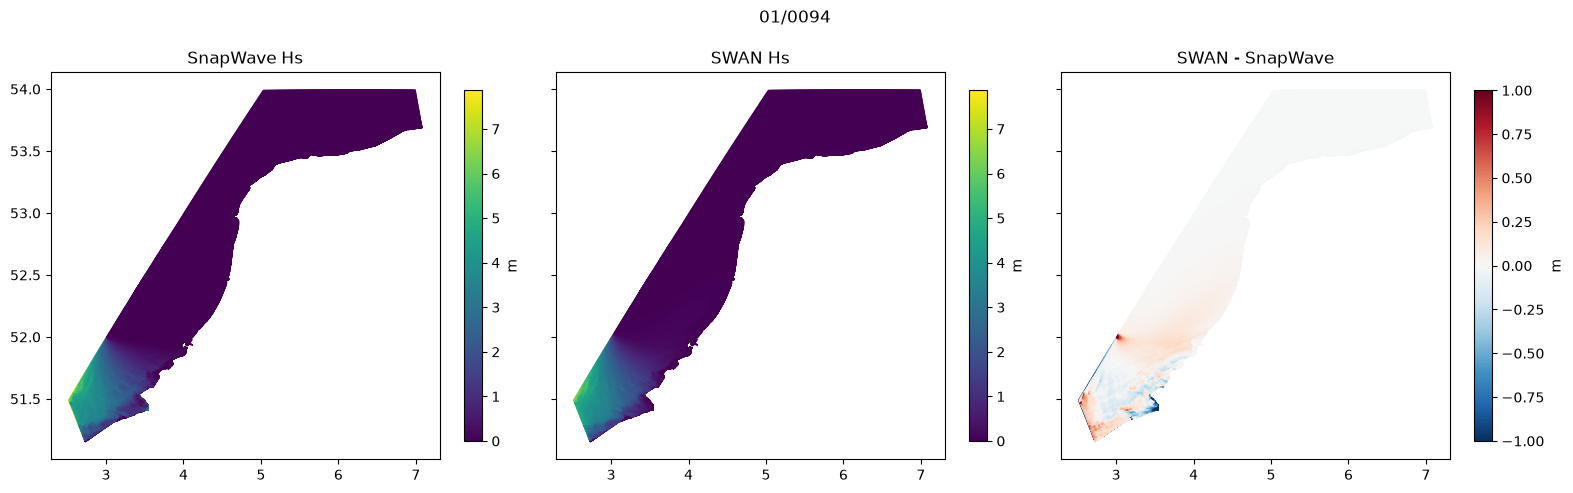

In [8]:
rows = mc.map_rows(snapwave)
folders = mc.case_folders(snapwave)
print(f"{len(rows)} cases with a map in both models")

strongest = int(snapwave["hs_forcing"].sel(case_num=rows).idxmax())
mc.plot_map_comparison(folders[strongest]);

ratio 0.00


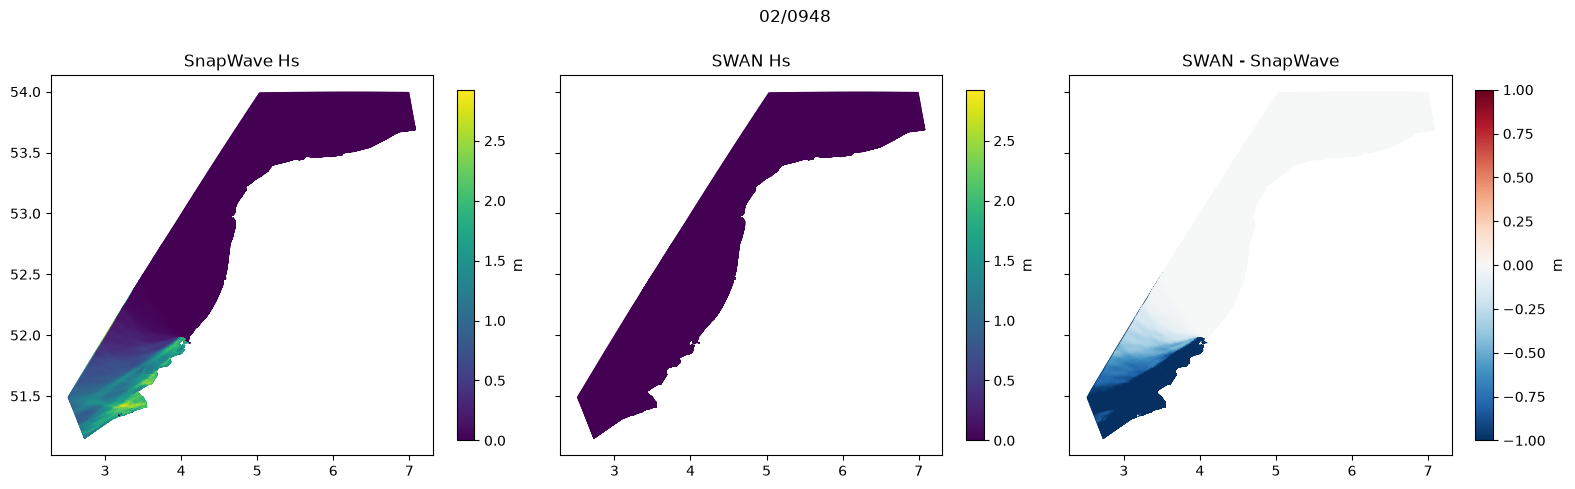

In [9]:
ratio = mc.hs_ratio(energetic_hs, swan["hs"], "sites").sel(case_num=rows)
furthest = int(abs(np.log(ratio)).idxmax())
print(f"ratio {float(ratio.sel(case_num=furthest)):.2f}")
mc.plot_map_comparison(folders[furthest]);

## 6 · Cost per case

In [10]:
mc.runtimes(snapwave)

,SnapWave,SWAN
count,300.000000,300.000
50%,0.150000,14.625
max,0.266667,39.350
